# 02 FMA k-means clustering: choosing k, agreement with genres, and what unsupervised structure recovers (training split)

In [1]:
import sys; sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from src.config import FIGURES, SEED
from src.data import load_fma, fma_xy
from src.evaluate import save_result

X, y = fma_xy(load_fma(), "training")
genres = sorted(y.unique())

# Standardise, then keep the components explaining 90% of variance (143 on our data, from notebook 01).
# Euclidean distance over 518 correlated, noisy features is dominated by redundant directions.
pca = PCA(n_components=0.90, random_state=SEED)
Z = pca.fit_transform(StandardScaler().fit_transform(X))
Z.shape

(6400, 143)

## 1. Choosing k

,inertia,silhouette
k,,
2,2.739041e+06,0.0900
3,2.623513e+06,0.0614
4,2.570173e+06,0.0453
5,2.525156e+06,0.0331
6,2.482656e+06,0.0376
7,2.441926e+06,0.0312
8,2.414134e+06,0.0281
9,2.381447e+06,0.0271
10,2.346013e+06,0.0258


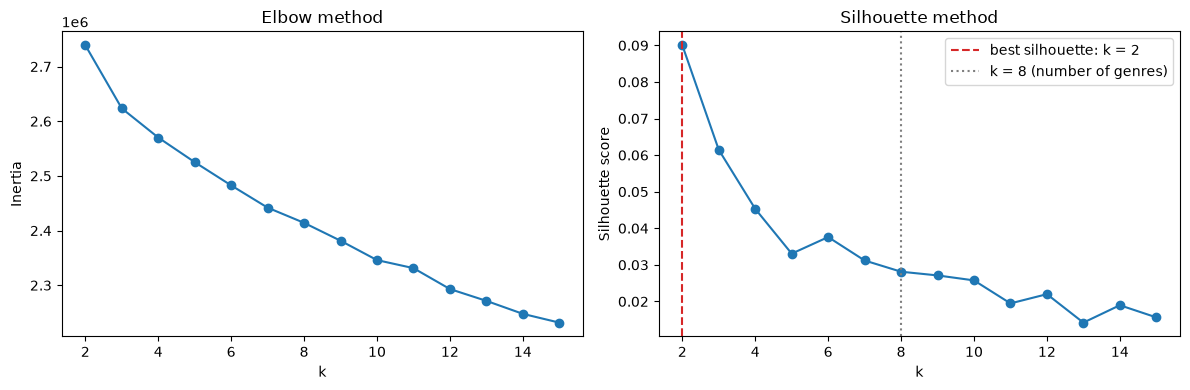

In [2]:
ks = range(2, 16)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(Z)
    inertia.append(km.inertia_)  # sum of squared distances of points to their cluster centre
    # Silhouette = (b - a) / max(a, b): a = mean distance within the cluster, b = to the nearest other cluster.
    silhouette.append(silhouette_score(Z, km.labels_, sample_size=3000, random_state=SEED))
best_k = ks[int(np.argmax(silhouette))]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(ks, inertia, "o-")
a1.set(xlabel="k", ylabel="Inertia", title="Elbow method")
a2.plot(ks, silhouette, "o-")
a2.axvline(best_k, color="tab:red", ls="--", label=f"best silhouette: k = {best_k}")
a2.axvline(8, color="tab:gray", ls=":", label="k = 8 (number of genres)")
a2.set(xlabel="k", ylabel="Silhouette score", title="Silhouette method")
a2.legend()
fig.tight_layout()
fig.savefig(FIGURES / "fma_kmeans_k_selection.png", dpi=200)
pd.DataFrame({"inertia": inertia, "silhouette": silhouette}, index=pd.Index(ks, name="k")).round(4)

We pick k by the highest silhouette score and check it against the elbow. We also run k = 8 to test whether the data's natural clusters line up with the 8 genres.

## 2. Do the clusters match the genres? (k = 8)

In [3]:
km8 = KMeans(n_clusters=8, init="k-means++", n_init=10, random_state=SEED).fit(Z)
clusters = km8.labels_
# ARI: agreement between two partitions corrected for chance (0 = random, 1 = identical).
# NMI: shared information between clusters and genres, scaled to 0-1.
scores = {"ari": adjusted_rand_score(y, clusters),
          "nmi": normalized_mutual_info_score(y, clusters),
          "silhouette": silhouette_score(Z, clusters, sample_size=3000, random_state=SEED),
          "inertia": km8.inertia_}
scores = {k: round(float(v), 4) + 0.0 for k, v in scores.items()}  # + 0.0 turns -0.0 into 0.0
save_result("kmeans_k8", "fma_clustering", scores,
            params={"k": 8, "pca_components": int(pca.n_components_), "best_silhouette_k": int(best_k)},
            split="training")
scores

{'ari': 0.0808, 'nmi': 0.1327, 'silhouette': 0.0281, 'inertia': 2414134.1844}

,size,top genres
cluster,,
0,1358,"Hip-Hop 30%, Electronic 22%"
1,189,"Instrumental 26%, Experimental 26%"
2,945,"Folk 26%, Instrumental 23%"
3,243,"Experimental 34%, Rock 33%"
4,1113,"Folk 32%, Instrumental 29%"
5,1344,"Rock 21%, International 18%"
6,1,"Experimental 100%, Electronic 0%"
7,1207,"Rock 24%, Electronic 23%"


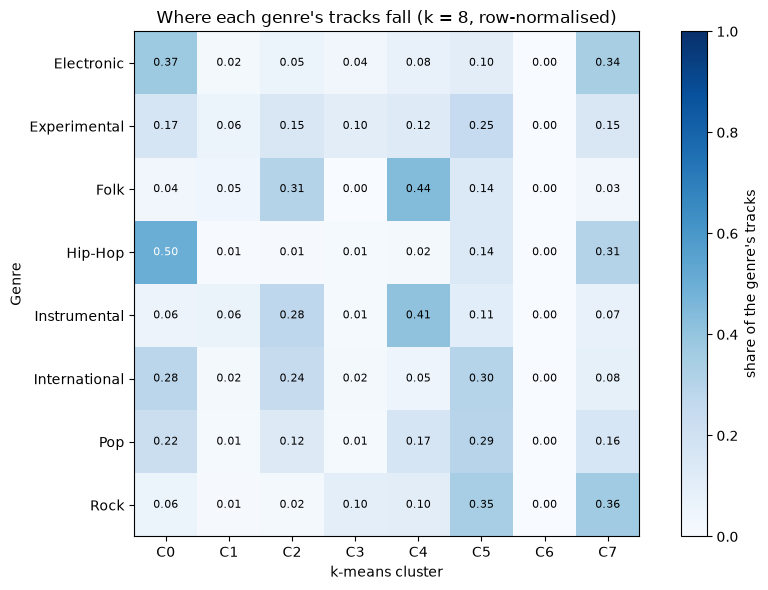

In [4]:
# Share of each genre's tracks that fall in each cluster (rows sum to 1).
table = pd.crosstab(pd.Series(y.to_numpy(), name="genre"), pd.Series(clusters, name="cluster"), normalize="index")
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(table, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(8), [f"C{c}" for c in table.columns])
ax.set_yticks(range(len(genres)), table.index)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        v = table.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="w" if v > 0.5 else "k")
fig.colorbar(im, label="share of the genre's tracks")
ax.set(xlabel="k-means cluster", ylabel="Genre", title="Where each genre's tracks fall (k = 8, row-normalised)")
fig.tight_layout()
fig.savefig(FIGURES / "fma_kmeans_contingency.png", dpi=200)

# Genre make-up of each cluster: the two largest genres and their share of the cluster.
counts = pd.crosstab(clusters, y.to_numpy())
pd.DataFrame({"size": counts.sum(axis=1),
              "top genres": [", ".join(f"{g} {p:.0%}" for g, p in (row / row.sum()).nlargest(2).items())
                             for _, row in counts.iterrows()]}).rename_axis("cluster")

## 3. Clusters vs genres in two dimensions

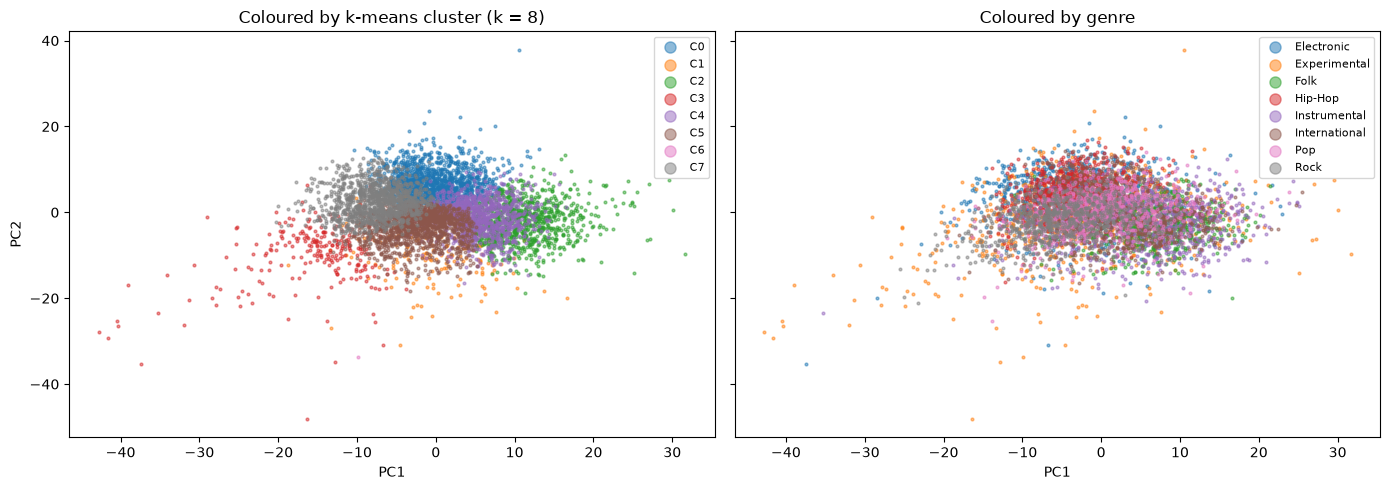

In [5]:
pcs = Z[:, :2]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for c in range(8):
    m = clusters == c
    a1.scatter(pcs[m, 0], pcs[m, 1], s=4, alpha=0.5, label=f"C{c}")
for g in genres:
    m = (y == g).to_numpy()
    a2.scatter(pcs[m, 0], pcs[m, 1], s=4, alpha=0.5, label=g)
a1.set(xlabel="PC1", ylabel="PC2", title="Coloured by k-means cluster (k = 8)")
a2.set(xlabel="PC1", title="Coloured by genre")
for a in (a1, a2):
    a.legend(markerscale=4, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "fma_kmeans_pca.png", dpi=200)

## 4. Clustering vs classification

k-means only sees distances between feature vectors. It splits the data along its largest sources of variation, such as loudness and brightness, which cut across genre labels. Classifiers use the labels to learn which directions separate genres. Low ARI and NMI therefore mean that genre is not the dominant structure in these features, not that genres are unlearnable. The supervised models in notebook 03 test that directly. k-means also assigns every track to exactly one cluster (hard assignment), although many tracks sit between genres.

## Findings

- **Best k by silhouette, and what the elbow shows:** the silhouette is highest at k = 2 (0.090) and falls as k grows, so it favours a coarse two-way split. The inertia curve falls smoothly with no clear elbow, so the elbow does not point to a better k and does not agree with k = 8.
- **Agreement with genres at k = 8 (ARI, NMI):** ARI = 0.081 and NMI = 0.133, with a silhouette of 0.028. All three are low, so the k-means clusters barely match the 8 genres.
- **Which genres share clusters, and which have a cluster of their own:** Folk and Instrumental share clusters 2 and 4. Hip-Hop and Electronic share cluster 0. Rock, Electronic and International are mixed across clusters 5 and 7, and Experimental is split across clusters 1 and 3 with Instrumental and Rock. No genre has a cluster of its own. Hip-Hop comes closest (30% of cluster 0), and cluster 6 is a single outlier track.
- **What this means for the supervised models:** the genres overlap heavily in feature space, as the Phase 1 PCA also showed. Unsupervised structure does not recover the labels, so any separation has to come from supervised models, and we should expect confusions between the overlapping genres above.